# Are bakery sales higher during Kiel Week?

This notebook compares daily turnover at one Kiel bakery branch on Kiel Week dates and other opening days. It summarizes all recorded sales from July 2013 to July 2018, then tests the hypothesis on the project's training years using the approach in the [project canvas](../CANVAS.md).

The [course dataset](https://raw.githubusercontent.com/opencampus-sh/intro-to-data-science-and-ml/main/data/bakery/README.md) reports turnover by date and product group. The source leaves the currency unspecified.

## Separate Kiel Week from other opening days

Join the festival calendar to the sales by date. Dates absent from the calendar count as other days. Sum the recorded product-group turnover for each date so one observation represents one opening day. Days without any sales rows are outside the comparison, and missing product-group rows stay unfilled.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from IPython.display import display
from matplotlib.ticker import PercentFormatter, StrMethodFormatter
from scipy import stats

BASE_URL = "https://raw.githubusercontent.com/opencampus-sh/intro-to-data-science-and-ml/main/data/bakery/"
TRAIN_START = pd.Timestamp("2013-07-01")
TRAIN_END = pd.Timestamp("2017-07-31")
WEEKDAYS = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
COLORS = {"Kiel Week": "#087f72", "Other days": "#607387"}

sales = pd.read_csv(BASE_URL + "umsatzdaten_gekuerzt.csv", parse_dates=["Datum"])
kiel_week_dates = pd.read_csv(BASE_URL + "kiwo.csv", parse_dates=["Datum"])

tagged_sales = sales.merge(kiel_week_dates, on="Datum", how="left", validate="many_to_one")
tagged_sales["KielerWoche"] = tagged_sales["KielerWoche"].fillna(0).astype(int)
daily_sales = (
    tagged_sales.groupby(["Datum", "KielerWoche"], as_index=False)
    .agg(turnover=("Umsatz", "sum"), product_groups=("Warengruppe", "nunique"))
    .sort_values("Datum")
)

kiel_week_sales = daily_sales.loc[daily_sales["KielerWoche"].eq(1)].copy()
other_days_sales = daily_sales.loc[daily_sales["KielerWoche"].eq(0)].copy()

period_sales = {"Kiel Week": kiel_week_sales, "Other days": other_days_sales}
display(pd.concat(
    [days[["Datum", "turnover", "product_groups"]].head(3) for days in period_sales.values()],
    keys=period_sales,
    names=["Period", "Row"],
).round({"turnover": 2}))

Datum  turnover  product_groups
Period     Row                                     
Kiel Week  347 2014-06-21   1573.93               5
           348 2014-06-22   1556.35               5
           349 2014-06-23   1254.34               5
Other days 0   2013-07-01   1269.25               5
           1   2013-07-02   1430.01               5
           2   2013-07-03   1124.27               5

## Compare daily turnover

The table reports the mean, median, and sample standard deviation for each period. The standard deviation describes how much turnover varies from day to day. The box plot shows the middle half of the daily values, the median line, and the mean diamond. The full-period comparison mixes seasons, weekdays, and the product groups available on each day.

In [2]:
turnover_by_period = {
    period: days["turnover"] for period, days in period_sales.items()
}
summary = pd.DataFrame({
    period: turnover.agg(["count", "mean", "median", "std"])
    for period, turnover in turnover_by_period.items()
}).T.rename(columns={
    "count": "Opening days",
    "mean": "Mean",
    "median": "Median",
    "std": "Standard deviation",
})
summary["Opening days"] = summary["Opening days"].astype(int)
summary.index.name = "Period"
display(summary.round(2))

raw_difference = summary.loc["Kiel Week", "Mean"] - summary.loc["Other days", "Mean"]
raw_difference_pct = 100 * raw_difference / summary.loc["Other days", "Mean"]
print(f"Kiel Week mean minus other days: {raw_difference:+,.2f} ({raw_difference_pct:+.1f}%).")

,Opening days,Mean,Median,Standard deviation
Period,,,,
Kiel Week,45,1291.22,1225.36,258.07
Other days,1774,1055.07,990.73,288.72


Kiel Week mean minus other days: +236.15 (+22.4%).


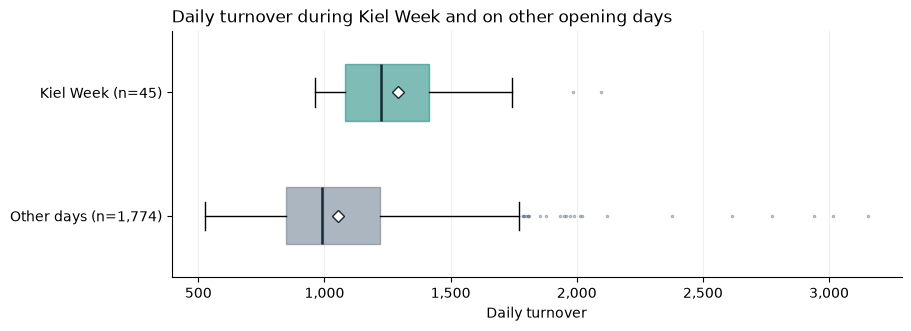

In [3]:
plot_periods = ["Other days", "Kiel Week"]
fig, ax = plt.subplots(figsize=(9, 3.2), layout="constrained")
box = ax.boxplot(
    [turnover_by_period[period] for period in plot_periods],
    orientation="horizontal",
    tick_labels=[f"{period} (n={len(turnover_by_period[period]):,})" for period in plot_periods],
    patch_artist=True,
    showmeans=True,
    widths=0.46,
    medianprops={"color": "#182832", "linewidth": 1.8},
    meanprops={"marker": "D", "markerfacecolor": "white", "markeredgecolor": "#182832"},
    flierprops={"marker": ".", "markersize": 3, "markeredgecolor": "#607387", "alpha": 0.55},
)

for patch, period in zip(box["boxes"], plot_periods):
    patch.set(facecolor=COLORS[period], edgecolor=COLORS[period], alpha=0.52)

ax.set_title("Daily turnover during Kiel Week and on other opening days", loc="left")
ax.set_xlabel("Daily turnover")
ax.xaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

## Test whether turnover is higher during Kiel Week

Kiel Week happens in summer, when turnover is already higher. Following the project canvas, the test uses the training period (July 2013 through July 2017) and compares daily totals on dates with all five regular product groups recorded. This gives each daily total the same product coverage. The 2018 festival appears in the full-period summary only.

A linear regression on the **log of daily turnover** adjusts for weekday, month, and year. The null hypothesis is that the adjusted Kiel Week difference is zero or lower. The alternative is that it is higher. Exponentiating the coefficient expresses the difference as a percentage in adjusted geometric mean turnover.

The regression uses Newey–West standard errors with nine observation lags, roughly one festival's length, to allow for short-range dependence between nearby days. The p-value is one-sided for the higher-sales hypothesis. The 95% confidence interval is two-sided. [Statsmodels documentation](https://www.statsmodels.org/stable/generated/statsmodels.regression.linear_model.OLSResults.get_robustcov_results.html)

In [4]:
model_days = (
    tagged_sales.loc[
        tagged_sales["Datum"].between(TRAIN_START, TRAIN_END)
        & tagged_sales["Warengruppe"].between(1, 5)
    ]
    .groupby(["Datum", "KielerWoche"], as_index=False)
    .agg(turnover=("Umsatz", "sum"), groups_recorded=("Warengruppe", "nunique"))
    .query("groups_recorded == 5")
    .sort_values("Datum")
    .assign(
        log_turnover=lambda days: np.log(days["turnover"]),
        weekday=lambda days: pd.Categorical(days["Datum"].dt.day_name(), categories=WEEKDAYS),
        month=lambda days: days["Datum"].dt.month,
        year=lambda days: days["Datum"].dt.year,
    )
)

model = smf.ols(
    "log_turnover ~ KielerWoche + C(weekday) + C(month) + C(year)", data=model_days
).fit(cov_type="HAC", cov_kwds={"maxlags": 9}, use_t=True)

adjusted_difference_pct = 100 * np.expm1(model.params["KielerWoche"])
ci_low, ci_high = 100 * np.expm1(model.conf_int().loc["KielerWoche"])
regression_p = stats.t.sf(model.tvalues["KielerWoche"], df=model.df_resid)

print(f"Training opening days: {len(model_days):,} ({model_days['KielerWoche'].sum()} Kiel Week days)")
print(f"Adjusted Kiel Week difference: {adjusted_difference_pct:+.1f}%")
print(f"95% confidence interval: {ci_low:+.1f}% to {ci_high:+.1f}%")
print(f"One-sided p-value: {regression_p:.3g}")

Training opening days: 1,409 (34 Kiel Week days)
Adjusted Kiel Week difference: +14.7%
95% confidence interval: +10.3% to +19.2%
One-sided p-value: 3.85e-12


## Compare each festival with nearby weekdays

For each eligible festival day, find the same weekday three weeks before and three weeks after. Keep pairs of comparison dates where both have all five regular product groups recorded. Average those two reference values for each festival day, then compare mean turnover within each festival year.

An exact sign test counts how often the festival mean is higher, giving each year one vote and dropping ties. Under its null hypothesis, a positive difference is no more likely than a negative one. The test assumes the yearly comparisons are independent. [SciPy documentation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.binomtest.html)

In [5]:
festival_days = model_days.loc[
    model_days["KielerWoche"].eq(1), ["Datum", "year", "turnover"]
].copy()
reference = model_days.loc[model_days["KielerWoche"].eq(0)].set_index("Datum")["turnover"]
three_weeks = pd.Timedelta(weeks=3)

festival_days["before"] = (festival_days["Datum"] - three_weeks).map(reference)
festival_days["after"] = (festival_days["Datum"] + three_weeks).map(reference)
matched_days = festival_days.dropna(subset=["before", "after"]).assign(
    reference_turnover=lambda days: (days["before"] + days["after"]) / 2
)

yearly = matched_days.groupby("year").agg(
    matched_days=("Datum", "size"),
    kiel_week_mean=("turnover", "mean"),
    nearby_mean=("reference_turnover", "mean"),
)
yearly["difference_pct"] = 100 * (yearly["kiel_week_mean"] / yearly["nearby_mean"] - 1)
display(yearly.rename(
    columns={
        "matched_days": "Matched days",
        "kiel_week_mean": "Kiel Week mean",
        "nearby_mean": "Nearby weekdays mean",
        "difference_pct": "Difference (%)",
    }
).rename_axis("Year").round(2))

differences = yearly["difference_pct"]
positive_years = int(differences.gt(0).sum())
non_tied_years = int(differences.ne(0).sum())
sign_test = stats.binomtest(positive_years, non_tied_years, p=0.5, alternative="greater")
print(f"Years with higher Kiel Week turnover: {positive_years}/{non_tied_years} non-tied years")
print(f"One-sided exact sign test p-value: {sign_test.pvalue:.4f}")

,Matched days,Kiel Week mean,Nearby weekdays mean,Difference (%)
Year,,,,
2014,8,1494.14,1405.90,6.28
2015,7,1256.71,1163.73,7.99
2016,8,1201.26,1078.06,11.43
2017,9,1225.78,1139.08,7.61


Years with higher Kiel Week turnover: 4/4 non-tied years
One-sided exact sign test p-value: 0.0625


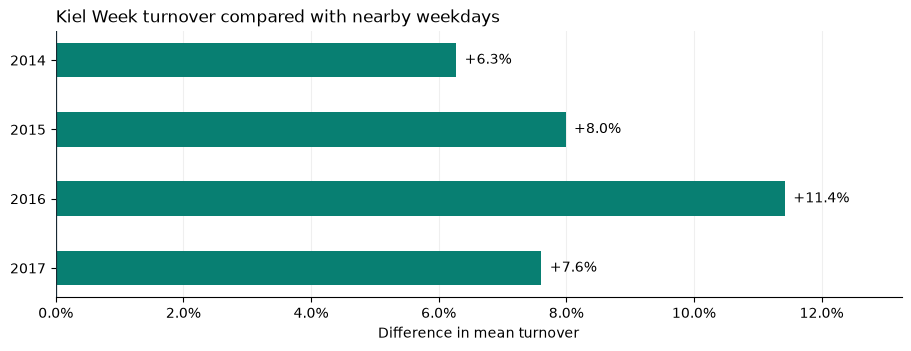

In [6]:
fig, ax = plt.subplots(figsize=(9, 3.4), layout="constrained")
bars = ax.barh(
    yearly.index.astype(str),
    differences,
    height=0.5,
    color=[COLORS["Kiel Week"] if change > 0 else COLORS["Other days"] for change in differences],
)
ax.bar_label(bars, labels=[f"{change:+.1f}%" for change in differences], padding=6)
ax.axvline(0, color="#182832", linewidth=0.9)
ax.invert_yaxis()
ax.margins(x=0.16)
ax.set_title("Kiel Week turnover compared with nearby weekdays", loc="left")
ax.set_xlabel("Difference in mean turnover")
ax.xaxis.set_major_formatter(PercentFormatter(xmax=100))
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)
ax.spines[["top", "right", "left"]].set_visible(False)
plt.show()

## Interpretation

Average recorded turnover was 22.4% higher during Kiel Week in the full-period comparison. The training-period regression estimated a 14.7% increase after adjusting for weekday, month, and year, with a 95% confidence interval of 10.3% to 19.2%.

Turnover was also higher in all four matched festival years. The exact sign test gave p = 0.0625, above the 5% significance level. Four festival years give limited evidence about how reliably the increase repeats. These observations cover one branch, and other factors that coincide with Kiel Week could contribute to the difference.